In [430]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
import datetime 

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

from sklearn.decomposition import PCA

In [431]:
# Semilla para reproducibilidad 
np.random.seed(42) 

In [432]:
# Número de clientes 
n_customers = 1000

In [433]:
# Generación de datos 
data = { 
'CustomerID': [f'CUST-{i+1:04d}' for i in range(n_customers)], 
'Age': np.random.randint(18, 70, size=n_customers), 
'AnnualIncome': np.random.randint(20, 150, size=n_customers), 
'SpendingScore': np.random.randint(1, 100, size=n_customers), 
'WebVisits': np.random.randint(0, 30, size=n_customers), 
'DaysSinceLastPurchase': np.random.randint(0, 365, size=n_customers), 
'EmailsOpened': np.random.randint(0, 100, size=n_customers),
'AdClicks': np.random.randint(0, 50, size=n_customers), 
'SocialMediaInteractions': np.random.randint(0, 200, size=n_customers), 
'AvgSessionDuration': np.round(np.random.uniform(1.0, 30.0, size=n_customers), 2), 
'ItemsInCart': np.random.randint(0, 15, size=n_customers) 
}

In [434]:
# Crear DataFrame y guardar en CSV 
df = pd.DataFrame(data) 
df.to_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\sena\GESTION DE DATOS EN MODELOS DE INTELIGENCIA ARTIFICIAL\quantum_customer_data.csv') 
print("Dataset 'quantum_customer_data.csv' generado con éxito.") 

Dataset 'quantum_customer_data.csv' generado con éxito.


In [435]:
ds=pd.read_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\sena\GESTION DE DATOS EN MODELOS DE INTELIGENCIA ARTIFICIAL\quantum_customer_data.csv')
ds.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Unnamed: 0               1000 non-null   int64  
 1   CustomerID               1000 non-null   str    
 2   Age                      1000 non-null   int64  
 3   AnnualIncome             1000 non-null   int64  
 4   SpendingScore            1000 non-null   int64  
 5   WebVisits                1000 non-null   int64  
 6   DaysSinceLastPurchase    1000 non-null   int64  
 7   EmailsOpened             1000 non-null   int64  
 8   AdClicks                 1000 non-null   int64  
 9   SocialMediaInteractions  1000 non-null   int64  
 10  AvgSessionDuration       1000 non-null   float64
 11  ItemsInCart              1000 non-null   int64  
dtypes: float64(1), int64(10), str(1)
memory usage: 93.9 KB


In [436]:
ds.describe()

,Unnamed: 0,Age,AnnualIncome,SpendingScore,WebVisits,DaysSinceLastPurchase,EmailsOpened,AdClicks,SocialMediaInteractions,AvgSessionDuration,ItemsInCart
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000
mean,499.500000,43.81900,83.095000,48.433000,14.415000,182.706000,49.866000,24.843000,99.942000,15.35975,6.936000
std,288.819436,14.99103,37.910621,29.164088,8.579533,105.563968,28.737186,14.306188,57.886747,8.38825,4.315383
min,0.000000,18.00000,20.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.11000,0.000000
25%,249.750000,31.00000,51.000000,22.000000,7.000000,90.750000,24.000000,13.000000,50.000000,8.04000,3.000000
50%,499.500000,44.00000,82.000000,47.000000,14.000000,180.000000,51.000000,24.000000,99.000000,15.30000,7.000000
75%,749.250000,56.00000,117.000000,73.000000,22.000000,277.000000,75.000000,38.000000,150.250000,22.51250,11.000000
max,999.000000,69.00000,149.000000,99.000000,29.000000,364.000000,99.000000,49.000000,199.000000,29.98000,14.000000


In [437]:
ds.isnull().sum()

Unnamed: 0                 0
CustomerID                 0
Age                        0
AnnualIncome               0
SpendingScore              0
WebVisits                  0
DaysSinceLastPurchase      0
EmailsOpened               0
AdClicks                   0
SocialMediaInteractions    0
AvgSessionDuration         0
ItemsInCart                0
dtype: int64

In [438]:
ds_numbers=ds[['Age','AnnualIncome','SpendingScore','WebVisits','DaysSinceLastPurchase','EmailsOpened','AdClicks','SocialMediaInteractions','AvgSessionDuration','ItemsInCart']]
ds_numbers.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      1000 non-null   int64  
 1   AnnualIncome             1000 non-null   int64  
 2   SpendingScore            1000 non-null   int64  
 3   WebVisits                1000 non-null   int64  
 4   DaysSinceLastPurchase    1000 non-null   int64  
 5   EmailsOpened             1000 non-null   int64  
 6   AdClicks                 1000 non-null   int64  
 7   SocialMediaInteractions  1000 non-null   int64  
 8   AvgSessionDuration       1000 non-null   float64
 9   ItemsInCart              1000 non-null   int64  
dtypes: float64(1), int64(9)
memory usage: 78.3 KB


In [439]:
x=np.linspace(0,5,11)
y=np.sin(x)

<Axes: xlabel='Age', ylabel='Count'>

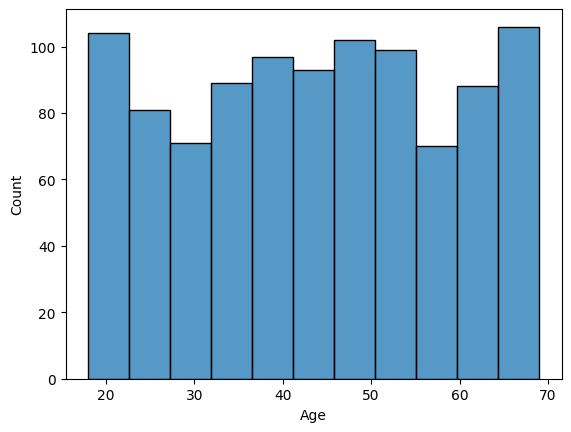

In [440]:
sns.histplot(ds_numbers['Age'])

<Axes: xlabel='AdClicks', ylabel='Count'>

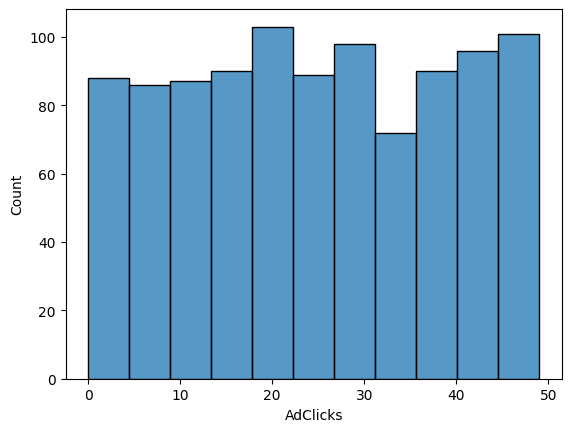

In [441]:
sns.histplot(ds_numbers['AdClicks'])

<Axes: xlabel='AnnualIncome', ylabel='Count'>

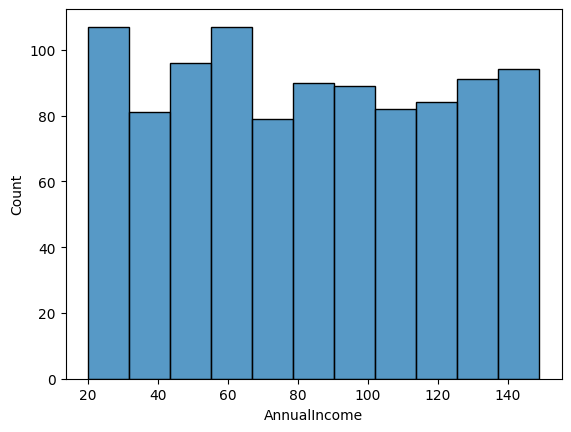

In [442]:
sns.histplot(ds_numbers['AnnualIncome'])

<Axes: xlabel='AvgSessionDuration', ylabel='Count'>

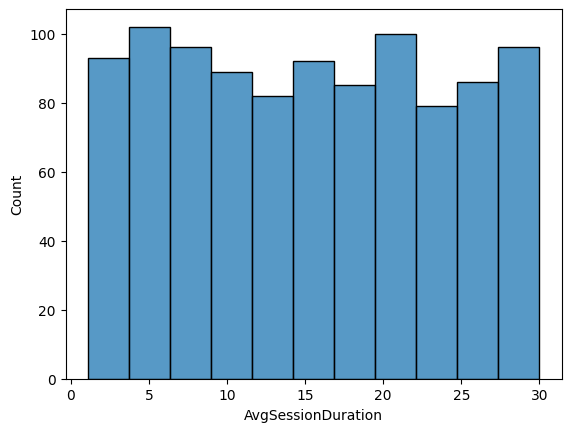

In [443]:
sns.histplot(ds_numbers['AvgSessionDuration'])

<Axes: xlabel='DaysSinceLastPurchase', ylabel='Count'>

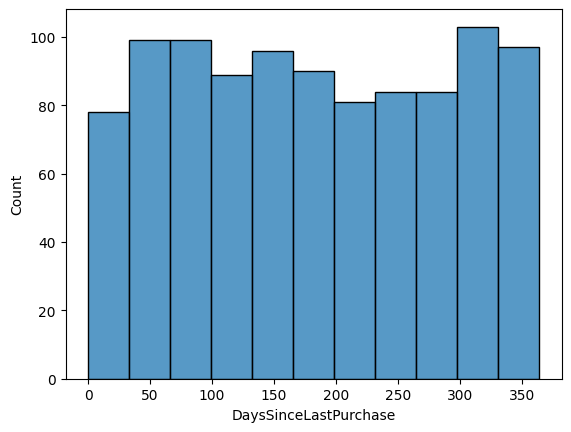

In [444]:
sns.histplot(ds_numbers['DaysSinceLastPurchase'])

<Axes: xlabel='EmailsOpened', ylabel='Count'>

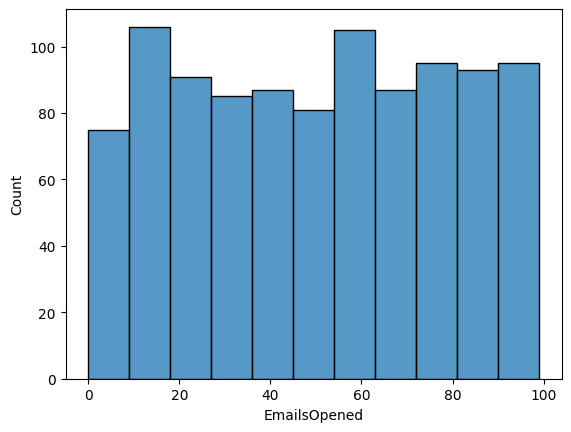

In [445]:
sns.histplot(ds_numbers['EmailsOpened'])

<Axes: xlabel='ItemsInCart', ylabel='Count'>

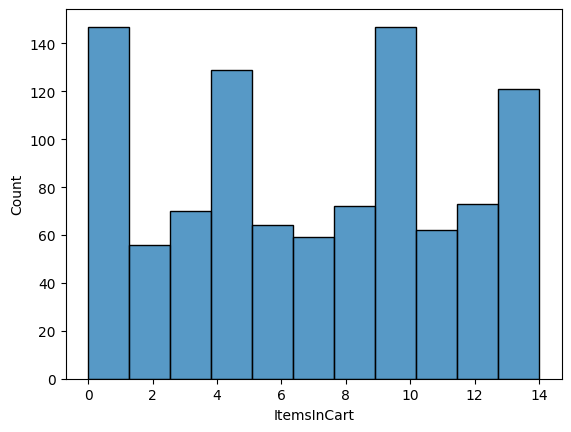

In [446]:
sns.histplot(ds_numbers['ItemsInCart'])

<Axes: xlabel='SocialMediaInteractions', ylabel='Count'>

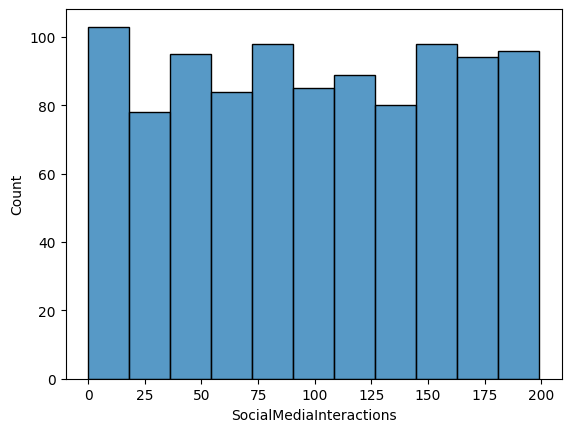

In [447]:
sns.histplot(ds_numbers['SocialMediaInteractions'])

<Axes: xlabel='SpendingScore', ylabel='Count'>

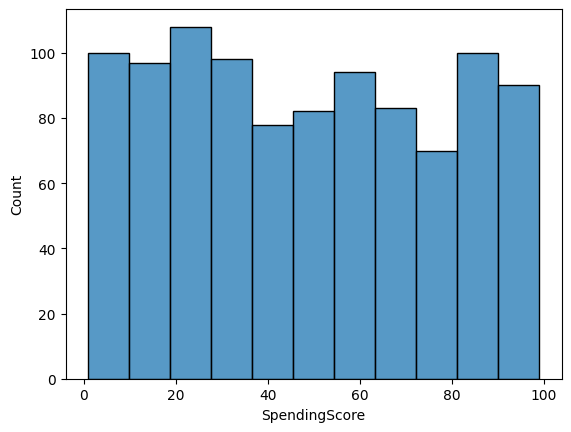

In [448]:
sns.histplot(ds_numbers['SpendingScore'])

<Axes: xlabel='WebVisits', ylabel='Count'>

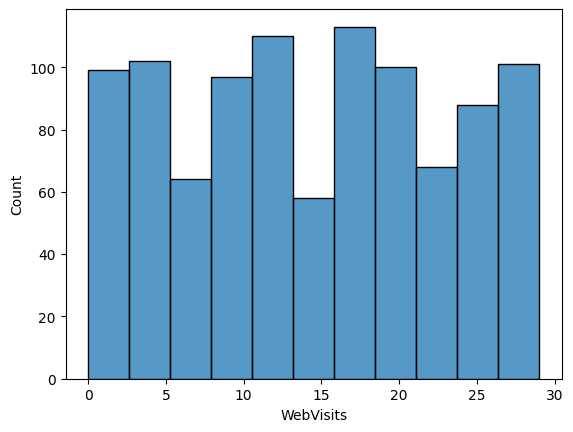

In [449]:
sns.histplot(ds_numbers['WebVisits'])

<Axes: >

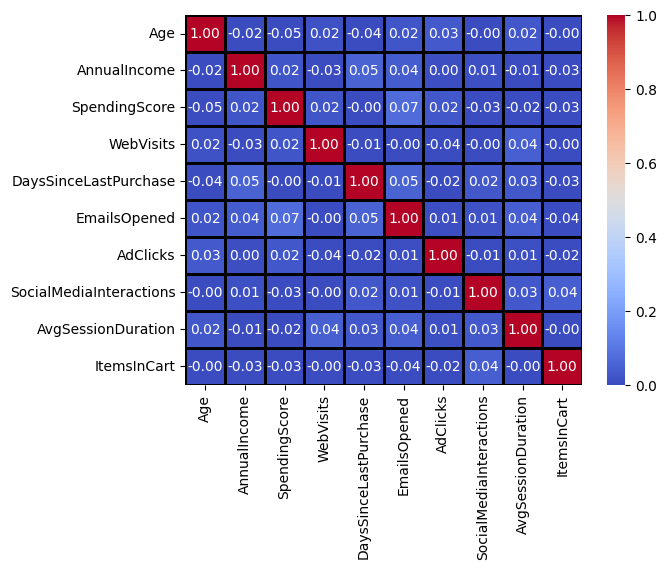

In [450]:
sns.heatmap(ds_numbers.corr(),annot=True,fmt='.2f',cmap='coolwarm',linewidths=1,linecolor='black',vmin=0,vmax=1,cbar=True,)

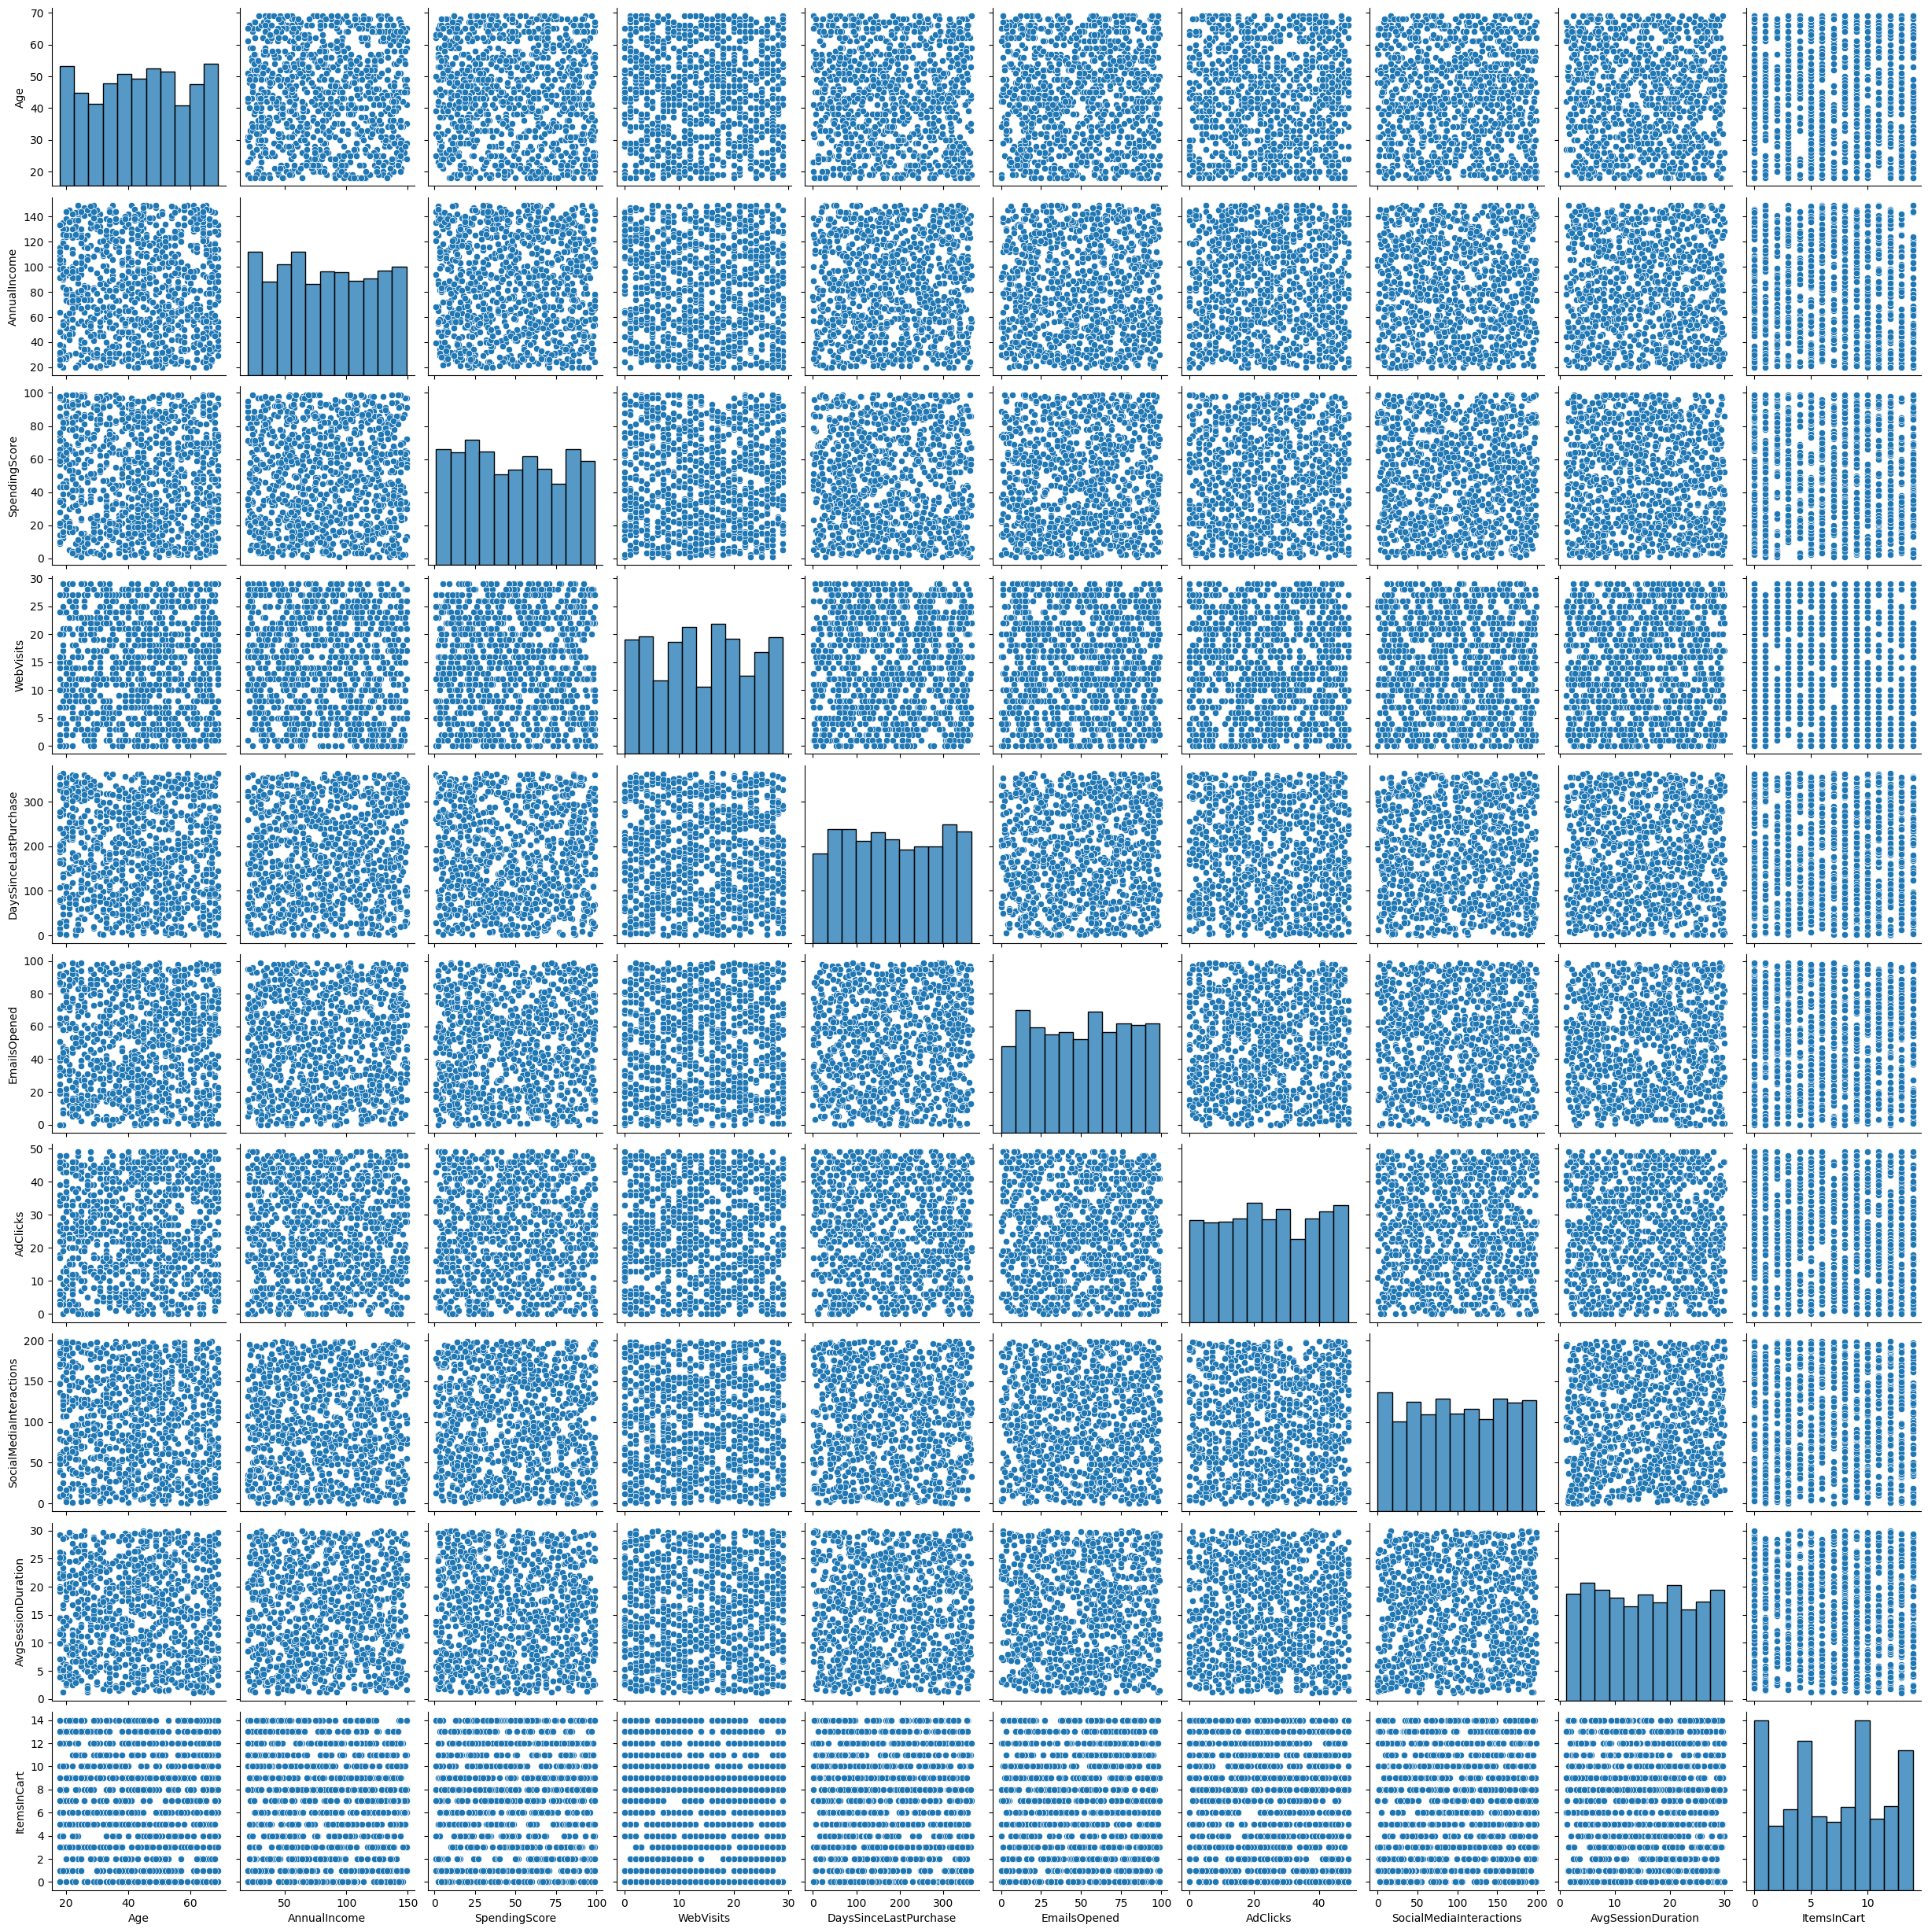

In [451]:
sns.pairplot(ds_numbers, height=2.5)
plt.show()

Estandarización

In [452]:
#Transforma para que los datos tengan una media de 0 y una desviación standar de 1.
cols_to_scale=['Age','AnnualIncome','SpendingScore','WebVisits','DaysSinceLastPurchase','EmailsOpened','AdClicks','SocialMediaInteractions','AvgSessionDuration','ItemsInCart']
scaler = StandardScaler()
ds_numbers[cols_to_scale]=scaler.fit_transform(ds_numbers[cols_to_scale])
ds_numbers


,Age,AnnualIncome,SpendingScore,WebVisits,DaysSinceLastPurchase,EmailsOpened,AdClicks,SocialMediaInteractions,AvgSessionDuration,ItemsInCart
0,0.812959,1.343435,-0.426525,-1.681002,-1.665283,-1.004985,-0.828238,-1.364414,-1.533834,-1.608078
1,1.680578,-1.295668,1.666135,0.651294,0.486148,-1.074616,-1.387716,0.433096,-1.542183,1.637754
2,0.145560,1.449000,-0.426525,1.584212,-0.717516,-1.492403,-0.968107,0.968893,-0.376876,0.246683
3,-0.788799,-0.952584,-1.558620,-0.748084,-0.215200,-0.761276,-0.688368,1.176298,-0.490186,-0.217007
4,1.079919,-0.662283,0.842793,1.584212,0.239728,-0.378306,-0.618433,-1.018739,-0.621388,0.478528
...,...,...,...,...,...,...,...,...,...,...
995,1.079919,0.103057,0.705569,1.700827,1.026375,0.631345,-1.317781,1.003460,0.058474,1.174064
996,1.346879,1.000352,-0.014854,-1.447773,-1.494685,0.596529,-0.478564,-1.347130,1.541050,-0.912542
997,1.213399,-0.583110,-0.975420,1.700827,-1.030280,-1.039801,-0.268759,-0.915037,-1.546954,1.637754
998,-0.588580,-0.847020,0.636958,-1.097928,1.708767,0.944685,0.640393,0.813339,-0.494957,-1.608078


La estandarización es importante porque transforma para que los datos tengan una media de 0 y una desviación standar de 1.

In [453]:
ds_numbers.describe()

,Age,AnnualIncome,SpendingScore,WebVisits,DaysSinceLastPurchase,EmailsOpened,AdClicks,SocialMediaInteractions,AvgSessionDuration,ItemsInCart
count,1.000000e+03,1.000000e+03,1.000000e+03,1.000000e+03,1.000000e+03,1.000000e+03,1.000000e+03,1.000000e+03,1.000000e+03,1.000000e+03
mean,-1.634248e-16,3.730349e-17,-1.421085e-17,1.154632e-16,1.048051e-16,1.421085e-17,-1.953993e-17,1.278977e-16,-7.105427e-18,-3.552714e-18
std,1.000500e+00,1.000500e+00,1.000500e+00,1.000500e+00,1.000500e+00,1.000500e+00,1.000500e+00,1.000500e+00,1.000500e+00,1.000500e+00
min,-1.723158e+00,-1.665142e+00,-1.627232e+00,-1.681002e+00,-1.731627e+00,-1.736111e+00,-1.737390e+00,-1.727373e+00,-1.699625e+00,-1.608078e+00
25%,-8.555393e-01,-8.470201e-01,-9.068079e-01,-8.646986e-01,-8.715286e-01,-9.005385e-01,-8.282378e-01,-8.631853e-01,-8.730561e-01,-9.125424e-01
50%,1.207993e-02,-2.889818e-02,-4.916036e-02,-4.839514e-02,-2.564657e-02,3.948081e-02,-5.895503e-02,-1.628130e-02,-7.126623e-03,1.483809e-02
75%,8.129592e-01,8.947879e-01,8.427931e-01,8.845231e-01,8.936873e-01,8.750535e-01,9.201321e-01,8.695112e-01,8.531373e-01,9.422186e-01
max,1.680578e+00,1.739301e+00,1.734747e+00,1.700827e+00,1.718245e+00,1.710626e+00,1.689415e+00,1.712094e+00,1.743816e+00,1.637754e+00


In [454]:
X_scaled=StandardScaler().fit_transform(ds_numbers)

pca = PCA()
X_pca = pca.fit_transform(X_scaled)

print(pca.explained_variance_ratio_)

pca.fit(X_scaled)

[0.11552863 0.10932415 0.10719795 0.10486966 0.10018555 0.09657942
 0.09467004 0.09348661 0.09167294 0.08648503]


,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",None
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized S

In [455]:
pca = PCA(n_components=0.95)
print(pca)

PCA(n_components=0.95)
